# Open or closed? What it takes to run a music model yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/08-open-vs-closed/notebook.ipynb)

Companion to the article *Open or Closed? What It Really Takes to Run an AI Music Model Yourself*. We estimate memory from parameter counts, load MusicGen-small and count what is really in it, measure its memory and speed on this machine, round its weights to fewer bits to see what breaks, and work out the cost of a song.

Runs on a CPU. The first run downloads about 2.4 GB (MusicGen-small).

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q librosa soundfile psutil "transformers>=4.45"

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr
import copy, os, time, psutil, torch
from transformers import AutoProcessor, MusicgenForConditionalGeneration, logging
logging.set_verbosity_error(); torch.set_grad_enabled(False)
ram = lambda: psutil.Process(os.getpid()).memory_info().rss / 1e9

## 1. Memory with a pencil

Memory for the weights = parameters x bytes per parameter. 32-bit floats take 4 bytes.

In [3]:
BYTES = {"32-bit": 4, "16-bit": 2, "8-bit": 1, "4-bit": 0.5}
MODELS = {"MusicGen-small (300M)": 300e6, "Stable Audio Open (about 1B)": 1.0e9, "DiffRhythm (1.1B)": 1.1e9, "MusicGen-medium (1.5B)": 1.5e9,
          "ACE-Step 1.5 (2B + 0.6B planner)": 2.6e9, "YuE2 (3B)": 3e9, "MusicGen-large (3.3B)": 3.3e9}
print(f"{'':34s}" + "".join(f"{k:>9s}" for k in BYTES))
for name, n in MODELS.items(): print(f"{name:34s}" + "".join(f"{n * b / 1e9:>7.1f}GB" for b in BYTES.values()))
print("\none attention map, frames x frames x 4 bytes:")
for label, n in (("30 s at 50 frames/s", 1500), ("3 minutes at 50 frames/s", 9000)): print(f"  {label:26s} {n * n * 4 / 1e6:>6,.0f} MB")

                                     32-bit   16-bit    8-bit    4-bit
MusicGen-small (300M)                 1.2GB    0.6GB    0.3GB    0.1GB
Stable Audio Open (about 1B)          4.0GB    2.0GB    1.0GB    0.5GB
DiffRhythm (1.1B)                     4.4GB    2.2GB    1.1GB    0.6GB
MusicGen-medium (1.5B)                6.0GB    3.0GB    1.5GB    0.8GB
ACE-Step 1.5 (2B + 0.6B planner)     10.4GB    5.2GB    2.6GB    1.3GB
YuE2 (3B)                            12.0GB    6.0GB    3.0GB    1.5GB
MusicGen-large (3.3B)                13.2GB    6.6GB    3.3GB    1.6GB

one attention map, frames x frames x 4 bytes:
  30 s at 50 frames/s             9 MB
  3 minutes at 50 frames/s      324 MB


## 2. What is really in the box

Load MusicGen-small and count. The name says 300M.

In [4]:
before = ram()
proc = AutoProcessor.from_pretrained("facebook/musicgen-small")
model = MusicgenForConditionalGeneration.from_pretrained("facebook/musicgen-small").eval()
count = lambda m: sum(p.numel() for p in m.parameters())
parts = {"text encoder (T5)": count(model.text_encoder), "language model": count(model.decoder) + count(model.enc_to_dec_proj), "codec (EnCodec)": count(model.audio_encoder)}
for k, v in parts.items(): print(f"{k:20s} {v / 1e6:>6.0f} M")
total = sum(parts.values())
print(f"{'total':20s} {total / 1e6:>6.0f} M  ->  {total * 4 / 1e9:.2f} GB at 4 bytes each")
print(f"memory of this process grew by {ram() - before:.2f} GB on loading")

text encoder (T5)       110 M
language model          422 M
codec (EnCodec)          57 M
total                   589 M  ->  2.36 GB at 4 bytes each
memory of this process grew by 0.55 GB on loading


## 3. Memory and speed while generating

Five seconds of music. The memory reading here includes this notebook's other libraries, so it runs a little higher than the script's clean-process measurement.

In [5]:
torch.manual_seed(0)
x = proc(text=["upbeat folk pop song with acoustic guitar, bass and drums"], return_tensors="pt")
t0 = time.time(); y = model.generate(**x, do_sample=True, guidance_scale=3, max_new_tokens=250)[0, 0].numpy(); dt = time.time() - t0
print(f"{len(y) / 32000:.1f} s of music in {dt:.0f} s = {dt / (len(y) / 32000):.1f} s of computing per second of music")
print(f"process memory now {ram():.2f} GB, against {total * 4 / 1e9:.2f} GB of weights")
display(Audio(y, rate=32000))

4.9 s of music in 22 s = 4.4 s of computing per second of music
process memory now 4.13 GB, against 2.36 GB of weights


[audio player: run the cell to listen]


## 4. Fewer bits per weight

By hand first: one weight, 0.37, in a row whose largest value is 1.0.

In [6]:
w, biggest = 0.37, 1.0
for bits in (3, 4, 8):
    levels = 2 ** (bits - 1) - 1; step = biggest / levels; stored = round(w / step)
    print(f"{bits} bits: {levels:>3d} levels each side, step {step:.5f}, stored as level {stored:>2d}, read back as {stored * step:.4f}, error {abs(stored * step - w):.4f}")

3 bits:   3 levels each side, step 0.33333, stored as level  1, read back as 0.3333, error 0.0367
4 bits:   7 levels each side, step 0.14286, stored as level  3, read back as 0.4286, error 0.0586
8 bits: 127 levels each side, step 0.00787, stored as level 47, read back as 0.3701, error 0.0001


Now every weight matrix of the language model, and a test on real music: how surprised is the model by the true next token (loss, lower is better), and how often does its top guess match the full-precision model's?

In [7]:
PAD, K = 2048, 4
CLIPS = {"pistachio": "ragtime piano", "vibeace": "a jazz combo with vibraphone, piano and bass", "brahms": "an orchestra playing a fast dance"}
def prepare(name, text):
    a, _ = clip(name, sr=32000, duration=10)
    f = proc(audio=[a], sampling_rate=32000, return_tensors="pt", padding=True)
    codes = model.audio_encoder.encode(f["input_values"], f["padding_mask"]).audio_codes[0, 0]
    T = codes.shape[1]; X = torch.full((K, T + K - 1), PAD)
    for k in range(K): X[k, k:k + T] = codes[k]                       # codebook k is delayed by k steps
    inp = torch.cat([torch.full((K, 1), PAD), X[:, :-1]], 1)
    t = proc(text=[text], return_tensors="pt", padding=True)
    return inp, X, model.enc_to_dec_proj(model.text_encoder(**t).last_hidden_state), t["attention_mask"]
data = [prepare(n, t) for n, t in CLIPS.items()]

def evaluate(decoder):
    losses, preds = [], []
    for inp, X, enc, mask in data:
        logits = decoder(input_ids=inp, encoder_hidden_states=enc, encoder_attention_mask=mask).logits.reshape(K, X.shape[1], -1)
        valid = X != PAD
        losses.append(torch.nn.functional.cross_entropy(logits[valid], X[valid]).item()); preds.append(logits[valid].argmax(-1))
    return float(np.mean(losses)), torch.cat(preds)

def rounded(decoder, bits):
    d = copy.deepcopy(decoder)
    for m in d.modules():
        if isinstance(m, torch.nn.Linear):
            wt = m.weight.data
            if bits == 16: m.weight.data = wt.half().float(); continue
            levels = 2 ** (bits - 1) - 1; scale = wt.abs().amax(dim=1, keepdim=True) / levels
            m.weight.data = torch.round(wt / scale).clamp(-levels, levels) * scale
    return d

n_lin = sum(m.weight.numel() for m in model.decoder.modules() if isinstance(m, torch.nn.Linear))
base_loss, base_pred = evaluate(model.decoder)
res = {32: (base_loss, 100.0)}
print(f"{'bits':>5s} {'size':>9s} {'loss':>7s} {'same top guess':>15s}   (uniform guess: {np.log(2048):.2f})")
print(f"{32:>5d} {n_lin * 4 / 1e6:>6.0f} MB {base_loss:>7.3f} {'100.0%':>15s}")
for bits in (16, 8, 6, 5, 4, 3):
    loss, pred = evaluate(rounded(model.decoder, bits)); agree = 100 * float((pred == base_pred).float().mean()); res[bits] = (loss, agree)
    print(f"{bits:>5d} {n_lin * bits / 8 / 1e6:>6.0f} MB {loss:>7.3f} {agree:>14.1f}%")

 bits      size    loss  same top guess   (uniform guess: 7.62)
   32   1644 MB   3.674          100.0%


   16    822 MB   3.674          100.0%


    8    411 MB   3.677           94.4%


    6    308 MB   3.730           77.5%


    5    257 MB   4.039           52.1%


    4    206 MB   6.538            8.3%


    3    154 MB   9.821            0.1%


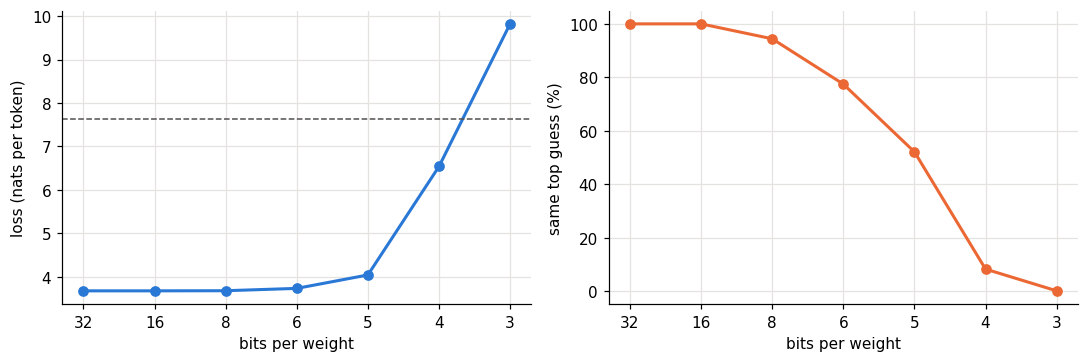

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); b = list(res)
ax[0].plot(range(len(b)), [res[k][0] for k in b], color=BLUE, marker="o"); ax[0].axhline(np.log(2048), color=INK2, ls="--", lw=1); ax[0].set_ylabel("loss (nats per token)")
ax[1].plot(range(len(b)), [res[k][1] for k in b], color=ORANGE, marker="o"); ax[1].set_ylabel("same top guess (%)")
for a in ax: a.set_xticks(range(len(b))); a.set_xticklabels(b); a.set_xlabel("bits per weight")
plt.tight_layout(); plt.show()

Hear it. The same prompt and seed with the language model's weights rounded to 8 bits and to 4 bits.

In [9]:
original = model.decoder
for bits in (8, 4):
    model.decoder = rounded(original, bits); torch.manual_seed(0)
    y = model.generate(**x, do_sample=True, guidance_scale=3, max_new_tokens=250)[0, 0].numpy()
    print(f"{bits} bits per weight"); display(Audio(y, rate=32000))
model.decoder = original

8 bits per weight


[audio player: run the cell to listen]


4 bits per weight


[audio player: run the cell to listen]


## 5. What a song costs

Edit the prices; they were checked in November 2026.

In [10]:
sub, credits, per_gen, songs_per_gen = 10.0, 2500, 10, 2
per_song = sub / (credits / per_gen * songs_per_gen)
print(f"subscription: ${sub:.0f} / {credits / per_gen * songs_per_gen:.0f} songs = ${per_song:.3f} per song")
for gpu, rate in (("RTX 4090", 0.89), ("A100", 2.09)):
    for label, sec in (("fast model, 10 s", 10), ("slow model, 36 min", 2160)): print(f"rented {gpu:9s} ${rate}/h, {label:20s} ${rate / 3600 * sec:.4f} per song")
month = 1800 / 36
print(f"own GPU: ${month:.0f} a month for 3 years -> break-even at {month / per_song:,.0f} songs a month")

subscription: $10 / 500 songs = $0.020 per song
rented RTX 4090  $0.89/h, fast model, 10 s     $0.0025 per song
rented RTX 4090  $0.89/h, slow model, 36 min   $0.5340 per song
rented A100      $2.09/h, fast model, 10 s     $0.0058 per song
rented A100      $2.09/h, slow model, 36 min   $1.2540 per song
own GPU: $50 a month for 3 years -> break-even at 2,500 songs a month
